In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [2]:
df = pd.read_csv("02 brainstroke.csv", usecols = ['age', 'avg_glucose_level', 'stroke'])

In [3]:
df.sample(8)

,age,avg_glucose_level,stroke
1290,49.0,82.41,0
1717,53.0,83.41,0
254,47.0,210.95,0
3748,56.0,87.50,0
4630,31.0,79.81,0
3914,65.0,95.87,0
1625,34.0,149.62,0
2946,9.0,90.22,0


In [4]:
df.isnull().sum()

age                  0
avg_glucose_level    0
stroke               0
dtype: int64

# Train/Test split

In [5]:
x = df.iloc[:, 0:2]
y = df.drop(x, axis = 'columns')
print(x.sample(5))

       age  avg_glucose_level
698   30.0              89.63
1719  34.0              86.51
784   58.0              76.99
4491  55.0              76.47
3874  26.0              71.25


In [6]:
print(y.sample(5))

      stroke
3267       0
4087       0
1865       0
631        0
2364       0


In [7]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2)

# Without applyinng bining

In [8]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier()

In [9]:
dt.fit(x_train, y_train)

DecisionTreeClassifier()

In [10]:
pred_b4 = dt.predict(x_test)

In [11]:
# Accuracy

from sklearn.metrics import accuracy_score

acc_b4 = accuracy_score(pred_b4, y_test)

print(acc_b4)

0.910958904109589


In [12]:
# Cross validation

from sklearn.model_selection import cross_val_score

cross_val_score(estimator = dt, X = x, y = y, cv = 10, scoring = 'accuracy').mean()

0.9123287671232877

# After bining.

In [13]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import KBinsDiscretizer

In [14]:
kbins_age = KBinsDiscretizer(n_bins = 10, encode = 'ordinal', strategy = 'quantile')
kbins_glucose = KBinsDiscretizer(n_bins = 10, encode = 'ordinal', strategy = 'uniform')

In [15]:
# creating transformer.

data = [
    ('Age', kbins_age, [0]),
    ('Glucose_level', kbins_glucose, [1])
]

In [16]:
ct = ColumnTransformer(transformers = data, remainder = 'passthrough')

In [17]:
x_train_trans = ct.fit_transform(x_train)
x_test_trans = ct.transform(x_test)

# Applying DecisionTree after bining.

In [18]:
dt_after = DecisionTreeClassifier()

In [19]:
dt_after.fit(x_train_trans, y_train)

DecisionTreeClassifier()

In [20]:
pred_after = dt_after.predict(x_test_trans)

In [21]:
acc_after = accuracy_score(pred_after, y_test)

print(acc_after)

0.949119373776908


In [22]:
cross_val_score(estimator = dt_after, X = x_train_trans, y = y_train, cv = 10, scoring = 'accuracy').mean()

0.9505872764753823

# Extracting some important informations.

In [23]:
print(ct.named_transformers_)

# 'named_transformers_' shows the value of transformers parameter.

{'Age': KBinsDiscretizer(encode='ordinal', n_bins=10), 'Glucose_level': KBinsDiscretizer(encode='ordinal', n_bins=10, strategy='uniform')}


In [24]:
print(ct.named_transformers_.Age)

# Shows info of transformers named 'Age'

KBinsDiscretizer(encode='ordinal', n_bins=10)


In [25]:
print(ct.named_transformers_.Age.n_bins_)

# 'n_bins_' shows no.of bins we applied.

[10]


In [26]:
print(ct.named_transformers_.Age.bin_edges_.tolist())

[array([8.0e-02, 1.0e+01, 2.0e+01, 3.0e+01, 3.7e+01, 4.4e+01, 5.1e+01,
       5.7e+01, 6.4e+01, 7.5e+01, 8.2e+01])]


In [27]:
print(ct.named_transformers_.Glucose_level.bin_edges_)

[array([ 55.12 ,  76.782,  98.444, 120.106, 141.768, 163.43 , 185.092,
        206.754, 228.416, 250.078, 271.74 ])                          ]


In [42]:
x_train_trans

array([[5., 1.],
       [8., 2.],
       [9., 2.],
       ...,
       [0., 0.],
       [1., 0.],
       [1., 1.]])

In [59]:
x_train_trans[:, 1]

array([1., 2., 2., ..., 0., 0., 1.])

# Let's create a DataFrame showing data of before and after bining.

In [28]:
data = {
    'Age': x_train['age'],
    'Age_trans': x_train_trans[:, 0],
    'Avg_glucose_level': x_train['avg_glucose_level'],
    'Glucose_level_trans': x_train_trans[:, 1]
    
}

# x_train_trans[:, 0] This code give aall the rows of first column
# lly df.iloc[:, 0:2] gives all the rows of 0 to 2th(Excluding) column.

In [29]:
df.iloc[:, 0:2]

,age,avg_glucose_level
0,67.0,228.69
1,61.0,202.21
2,80.0,105.92
3,49.0,171.23
4,79.0,174.12
...,...,...
5105,80.0,83.75
5106,81.0,125.20
5107,35.0,82.99
5108,51.0,166.29


In [30]:
df_after = pd.DataFrame(data)

In [31]:
df_after

,Age,Age_trans,Avg_glucose_level,Glucose_level_trans
2049,50.0,5.0,82.37,1.0
4685,65.0,8.0,104.12,2.0
216,78.0,9.0,116.10,2.0
4610,26.0,2.0,59.67,0.0
1698,44.0,5.0,215.90,7.0
...,...,...,...,...
935,54.0,6.0,92.95,1.0
1033,34.0,3.0,108.47,2.0
3240,7.0,0.0,73.27,0.0
3835,17.0,1.0,60.57,0.0


In [32]:
df_after['Age_label'] = pd.cut(x = x_train['age'], bins = ct.named_transformers_.Age.bin_edges_[0].tolist())

In [33]:
df_after['Glucose_level_label']  = pd.cut(x = x_train['avg_glucose_level'], bins = ct.named_transformers_.Glucose_level.bin_edges_[0])

In [34]:
df_after[
(df_after['Glucose_level_trans'] == 2) |
(df_after['Glucose_level_trans'] == 3)
]

,Age,Age_trans,Avg_glucose_level,Glucose_level_trans,Age_label,Glucose_level_label
4685,65.0,8.0,104.12,2.0,"(64.0, 75.0]","(98.444, 120.106]"
216,78.0,9.0,116.10,2.0,"(75.0, 82.0]","(98.444, 120.106]"
3731,8.0,0.0,121.99,3.0,"(0.08, 10.0]","(120.106, 141.768]"
1095,18.0,1.0,103.94,2.0,"(10.0, 20.0]","(98.444, 120.106]"
186,63.0,7.0,116.69,2.0,"(57.0, 64.0]","(98.444, 120.106]"
...,...,...,...,...,...,...
346,68.0,8.0,116.23,2.0,"(64.0, 75.0]","(98.444, 120.106]"
1585,67.0,8.0,110.68,2.0,"(64.0, 75.0]","(98.444, 120.106]"
362,76.0,9.0,110.99,2.0,"(75.0, 82.0]","(98.444, 120.106]"
1881,62.0,7.0,130.56,3.0,"(57.0, 64.0]","(120.106, 141.768]"


In [35]:
ct.named_transformers_.Glucose_level.bin_edges_.tolist()

[array([ 55.12 ,  76.782,  98.444, 120.106, 141.768, 163.43 , 185.092,
        206.754, 228.416, 250.078, 271.74 ])]

In [36]:
ct.named_transformers_.Glucose_level.bin_edges_[0].tolist()

[55.12,
 76.782,
 98.44399999999999,
 120.106,
 141.768,
 163.43,
 185.09199999999998,
 206.754,
 228.416,
 250.078,
 271.74]

In [47]:
import matplotlib.pyplot as plt

Text(0.5, 1.0, 'Avg glucode level after binning.')

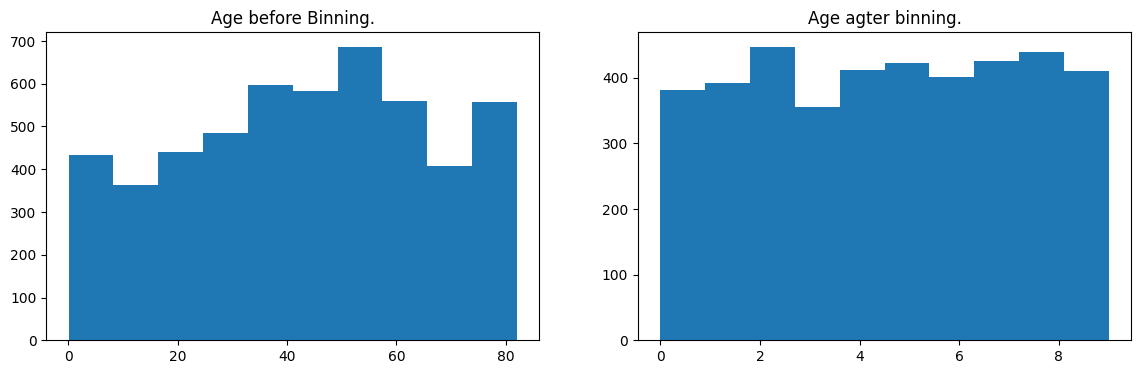

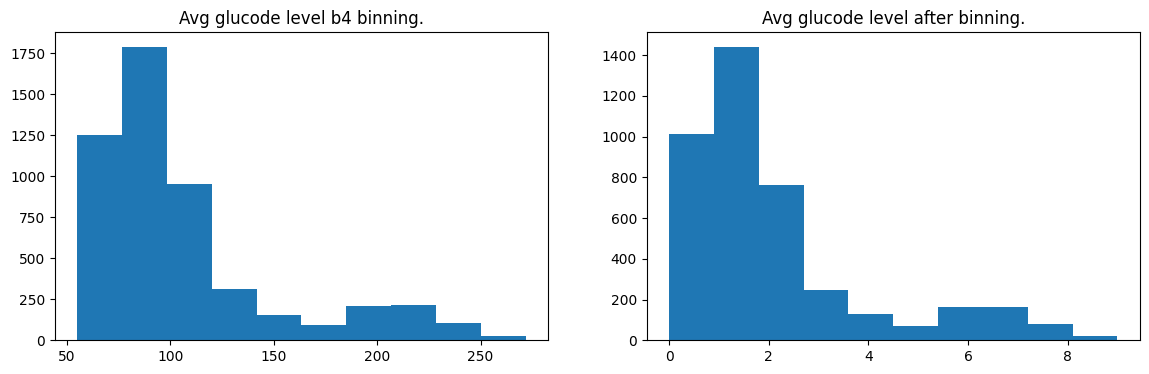

In [58]:
plt.figure(figsize = (14, 4))

plt.subplot(121)
plt.hist(x['age'])
plt.title("Age before Binning.")

plt.subplot(122)
plt.hist(x_train_trans[:, 0])
plt.title("Age agter binning.")

plt.figure(figsize = (14,4))

# Age
plt.subplot(121)
plt.hist(x['avg_glucose_level'])
plt.title("Avg glucode level b4 binning.")


# Avg_glucose_level
plt.subplot(122)
plt.hist(df_after['Glucose_level_trans'])
plt.title("Avg glucose level after binning.")

Text(0.5, 1.0, 'Age after binning.')

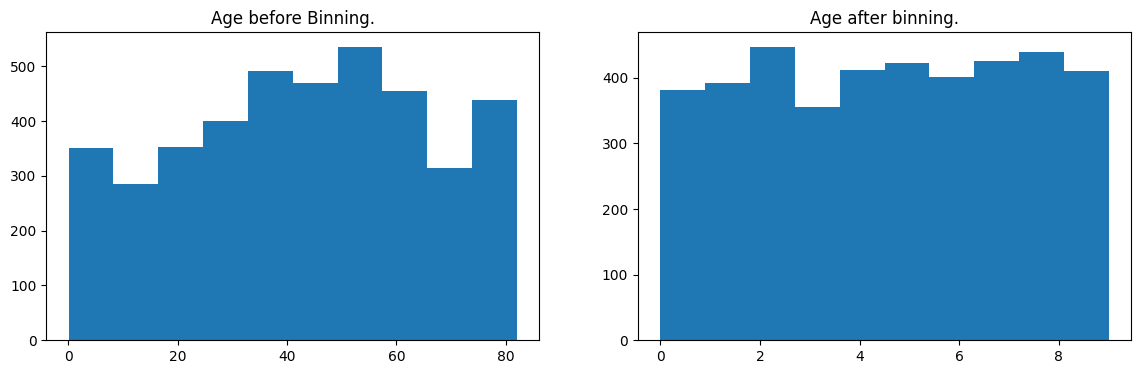

In [53]:
# Plotting the same from df_after.

plt.figure(figsize = (14, 4))

plt.subplot(121)
plt.hist(df_after['Age'])
plt.title("Age before Binning.")

plt.subplot(122)
plt.hist(df_after["Age_trans"])
plt.title("Age after binning.")